#  Lab 1: Abstraction Levels and the building blocks


</table>

## The four levels of abstraction

LangChain and LangGraph form 4 levels of abstraction, with each one built on the ones before. The terminology is confusing because 'LangChain' appears in a few places..

| Layer | Packages | What it gives you | What you control |
|---|---|---|---|
| 1. Building blocks | `langchain-core` + `langchain-openai` | chat models, the `@tool` decorator, messages, structured output | everything, including the tool loop by hand |
| 2. Orchestration | `langgraph` | a graph of steps, with state, memory and checkpointing | the control flow (you design the graph) |
| 3. Agent | `langchain` (`create_agent`) | the standard agent loop, prebuilt | just model, tools and a prompt |
| 4. Harness | `deepagents` (`create_deep_agent`) | an opinionated harness with planning, sub-agents and a filesystem | your intent |




# Today is Layer 1: the building blocks

This is where LangChain began: an abstraction layer, not unlike LiteLLM - but a more heavyweight version.

In [1]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from pydantic import BaseModel, Field

load_dotenv(override=True)

True

# A first model call

`ChatOpenAI` is the abstraction around OpenAI calls, and there are similar packages for other LLM providers.

We call `invoke` with a prompt; this is a key method in LangChain.

In [2]:
llm = ChatOpenAI(model="gpt-5-mini")

message = "AI 에이전트가 자율적이라는 것이 무슨 의미인지 한 문장으로 설명해줘"

reply = llm.invoke(message)

print(reply.content)

AI 에이전트가 자율적이라는 것은 인간의 지속적인 지시 없이 환경을 감지·이해하고 목표 달성을 위해 스스로 계획·의사결정·행동을 조정할 수 있다는 뜻이다.


In [7]:
from pprint import pprint
pprint(reply)

AIMessage(content='AI 에이전트가 자율적이라는 것은, 사람이 매번 지시하지 않아도 스스로 목표를 이해하고 판단해 행동을 수행할 수 있다는 뜻입니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 28, 'total_tokens': 68, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5.4-mini-2026-03-17', 'system_fingerprint': None, 'id': 'chatcmpl-EC0lptuFHWyNqQ1xlsbA3UyZl17j9', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019ff594-e388-74b3-829d-46302cf8310c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 28, 'output_tokens': 40, 'total_tokens': 68, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})


### Streaming

For a live, token by token feel, swap `invoke` for `stream` and loop over the chunks

In [ ]:
llm = ChatOpenAI(model="gpt-5-mini")
for chunk in llm.stream("자율 에이전트에 대한 두 줄짜리 시를 써줘"):
    print(chunk.content, end="", flush=True)

스스로 길을 고르며 끝없이 배우는 마음,  
명령 없이도 어둠 속에서 다음 문장을 찾는다.

# Any OpenAI-compatible provider

As before; we can use OpenAI compatible endpoints with the ChatOpenAI object

In [10]:
# 1. 필수 라이브러리 가져오기

from langchain_google_genai import ChatGoogleGenerativeAI  # Google Gemini 통합 라이브러리


# Chat LLM(언어 모델) 객체 생성
# - model: 사용할 모델 (gemini-2.5-flash)
# - temperature: 응답의 다양성 조절 (값이 높을수록 다양한 답변 생성)
# - max_tokens: 생성할 응답의 최대 토큰 수 (응답의 길이를 조절)
chat_llm2 = ChatGoogleGenerativeAI(model="gemini-2.5-flash", temperature=0.5, max_tokens=1024)

# 사용자 질문에 대한 응답 요청
question = "LangChain이 무엇인지 한 문장으로 설명해줘"

# invoke 메서드로 질문에 대한 답변 생성
response = chat_llm2.invoke(question)

# 생성된 답변 출력
print(response)


content='LangChain은 대규모 언어 모델(LLM)과 다양한 외부 구성 요소를 연결하여 복잡하고 지능적인 애플리케이션을 쉽게 구축하도록 돕는 프레임워크입니다.' additional_kwargs={} response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'} id='lc_run--019ff599-b086-75e3-8eb0-204c2e84c313-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 13, 'output_tokens': 935, 'total_tokens': 948, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 892}}


# Messages

LangChain comes with abstractions around SystemMessage, HumanMessage, AIMessage, although you can use the usual list-of-dicts instead.

In [3]:
llm = ChatOpenAI(model="gpt-5-mini")
messages = [
    SystemMessage("당신은 정확히 열 글자 이내로만 답하는 간결한 어시스턴트입니다."),
    HumanMessage("프랑스의 수도는 어디인가요?"),
]

print(llm.invoke(messages).content)


파리


In [ ]:
llm = ChatOpenAI(model="gpt-5-mini")
# 이미 익숙한 형식인 일반 딕셔너리를 사용한 동일한 호출
messages_as_dicts = [
    {"role": "system", "content": "당신은 정확히 열 글자 이내로만 답하는 간결한 어시스턴트입니다."},
    {"role": "user", "content": "프랑스의 수도는 어디인가요?"},
]
print(llm.invoke(messages_as_dicts).content)

파리입니다


# Tools with the `@tool` decorator

A tool is a Python function the model is allowed to call. The modern way to make one is the `@tool` decorator. Your docstring becomes the description the model reads, and your type hints become the argument schema, just like `@function_tool` with OpenAI Agents SDK.

This replaces the older `Tool(...)` wrapper from earlier versions of LangChain.

In [2]:
@tool
def get_share_price(symbol: str) -> float:
    """Return the current share price for a given ticker symbol."""
    fake_prices = {"AAPL": 241.5, "GOOG": 168.2, "AMZN": 198.0}
    return fake_prices.get(symbol.upper(), 0.0)


In [3]:

print("name:", get_share_price.name)
print("description:", get_share_price.description)
print("args:", get_share_price.args)
print("called directly:", get_share_price.invoke({"symbol": "AAPL"}))

name: get_share_price
description: Return the current share price for a given ticker symbol.
args: {'symbol': {'title': 'Symbol', 'type': 'string'}}
called directly: 241.5


# Giving tools to the model 동작X

This is a bit clunky; redemption will come in Day 3 when we use the create_agent features,

For now, we have to write the loop ourselves, rather like we did in Week 1.

The first step is to bind the tools to the model with `bind_tools`. Now when we invoke, the model may come back not with an answer but with a request to run a tool. That request shows up in `.tool_calls`.

In [6]:
llm = ChatOpenAI(model="gpt-5-mini")
llm_with_tools = llm.bind_tools([get_share_price])

response = llm_with_tools.invoke("What is the share price of Amazon?")


In [8]:
from pprint import pprint
pprint(response)

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 89, 'prompt_tokens': 138, 'total_tokens': 227, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ECfONpHUyI1t03lQSGsGIoglvCrIH', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019ffee3-90fd-7f30-9816-1af12c7134f7-0', tool_calls=[{'name': 'get_share_price', 'args': {'symbol': 'AMZN'}, 'id': 'call_rIYvKu3QxTz5CdA6dSqt1nKR', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 138, 'output_tokens': 89, 'total_tokens': 227, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reason

In [9]:

print("content:", repr(response.content))
print("tool_calls:", response.tool_calls)

content: ''
tool_calls: [{'name': 'get_share_price', 'args': {'symbol': 'AMZN'}, 'id': 'call_rIYvKu3QxTz5CdA6dSqt1nKR', 'type': 'tool_call'}]


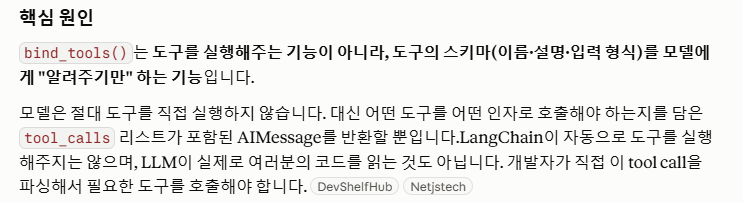

In [11]:
# 프롬프트로 강하게 지시해도
response = llm_with_tools.invoke(
    "Use the get_share_price tool to find the share price of Amazon. You must call the tool."
)


In [13]:
from pprint import pprint
pprint(response)

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 153, 'prompt_tokens': 150, 'total_tokens': 303, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 128, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ECfTfeJcEWk2aJ57a9jlKcro6mBT2', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019ffee8-91ae-7171-974e-6eb9df977c82-0', tool_calls=[{'name': 'get_share_price', 'args': {'symbol': 'AMZN'}, 'id': 'call_sNZlki4WqtLGrNj2eKjP0cfZ', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 150, 'output_tokens': 153, 'total_tokens': 303, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'rea

In [12]:
print(response.content)      # 여전히 "" (빈 문자열)
print(response.tool_calls)   # [{'name': 'get_share_price', 'args': {'symbol': 'AMZN'}, ...}]


[{'name': 'get_share_price', 'args': {'symbol': 'AMZN'}, 'id': 'call_sNZlki4WqtLGrNj2eKjP0cfZ', 'type': 'tool_call'}]


# Running the tool loop by hand

So now we need to write a little loop, quite similar to Week 1

In [4]:
llm = ChatOpenAI(model="gpt-5-mini")
llm_with_tools = llm.bind_tools([get_share_price])

# Start the conversation and keep the model's tool request in the history
conversation = [HumanMessage("What is the share price of Amazon?")]
ai_message = llm_with_tools.invoke(conversation)
conversation.append(ai_message)

# Run each requested tool and add its result as a ToolMessage
for call in ai_message.tool_calls:
    if call["name"] == "get_share_price":
        result = get_share_price.invoke(call["args"])
        conversation.append(ToolMessage(content=str(result), tool_call_id=call["id"]))

# Invoke again, now that the model can see the tool result
final = llm_with_tools.invoke(conversation)
print(final.content)

Amazon (AMZN) share price: $198.00.

Prices change quickly — would you like a real-time update, historical chart, or additional info (market cap, P/E, exchange)?


# Tool execution loop

https://docs.langchain.com/oss/python/langchain/models#tool-execution-loop


In [5]:
llm = ChatOpenAI(model="gpt-5-mini")
llm_with_tools = llm.bind_tools([get_share_price])

# 1단계: 모델이 tool_calls를 생성 (실제 함수 실행은 아직 안 됨)
messages = [{"role": "user", "content": "What is the share price of Amazon?"}]
ai_msg = llm_with_tools.invoke(messages)
messages.append(ai_msg)

# 2단계: 도구 실행 — call 전체를 넘기면 ToolMessage가 바로 반환됨
for tool_call in ai_msg.tool_calls:
    tool_result = get_share_price.invoke(tool_call)   # ToolMessage 객체
    messages.append(tool_result)

# 3단계: 도구 결과를 포함해 다시 모델 호출
final_response = llm_with_tools.invoke(messages)
print(final_response.text)

Amazon (AMZN): $198.00 per share.

Note: stock prices change constantly. If you want I can refresh the price, show recent intraday history, or get the price at a specific timestamp.


### Structured output

Similar to OpenAI Agents SDK, we can require the model to respond with a Pydantic subclass

In [15]:
llm = ChatOpenAI(model="gpt-5-mini")
class Company(BaseModel):
    name: str = Field(description="The company name")
    ticker: str = Field(description="The stock ticker symbol")
    founded_year: int = Field(description="The year the company was founded")

structured_llm = llm.with_structured_output(Company)

company = structured_llm.invoke("Tell me about Amazon the technology company")
print(company)
print("Just the ticker:", company.ticker)

name='Amazon.com, Inc.' ticker='AMZN' founded_year=1994
Just the ticker: AMZN
